# 🚗 Python EDA Task – Car Sales Dataset

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

In [3]:
df = pd.read_excel('JExiCarSales.xlsx')
df.head()

,InvoiceDate,Make,CountryName,IsDealer,SalePrice,CostPrice,TotalDiscount,DeliveryCharge,SpareParts,LaborCost,...,Model,Color,ReportingYear,ReportingMonth,Registration_Date,VehicleType,InvoiceNumber,CountryISOCode,OuterPostode,Region
0,2012-10-04,Rolls Royce,United Kingdom,NaN,95000,50000,500.0,750,500,750,...,Camargue,Red,2012,10,1985-01-08,Saloon,8B3D7F83-F42C-4523-A737-CDCBF7705B77,GBR,ST,East Midlands
1,2012-01-01,Aston Martin,United Kingdom,NaN,120000,75000,0.0,1500,600,550,...,DBS,Blue,2012,1,2007-05-09,Coupe,139BEEEF-FF32-4BE9-9EF1-819AC888B85C,GBR,EC,Greater London Authority
2,2012-02-02,Rolls Royce,United Kingdom,NaN,88000,75000,750.0,1000,750,550,...,Silver Ghost,Green,2012,2,2006-09-08,Saloon,D35D72CD-5FF3-4701-A6D1-265A4F4E7CD5,GBR,B,West Midlands
3,2012-03-03,Rolls Royce,United Kingdom,NaN,89000,88000,0.0,1000,85,550,...,Silver Ghost,Blue,2012,3,1987-01-05,Saloon,2ABAA300-E2A5-4E37-BFCA-7B80ED88A2BD,GBR,EC,Greater London Authority
4,2012-04-04,Rolls Royce,United Kingdom,NaN,92000,62000,0.0,1500,2500,550,...,Camargue,Canary Yellow,2012,4,1985-01-08,Saloon,A1C2D846-EC39-46FA-A399-0C194AAD4DC8,GBR,NE,Greater London Authority


# 1. Dataset Overview – rows, columns, data types, and basic information

In [4]:
#row
print(f"\nTotal Rows: {df.shape[0]}")


Total Rows: 457


In [5]:
#column
print(f"Total Columns: {df.shape[1]}")

Total Columns: 21


In [7]:
#data type
print("==========data type==========")
df.dtypes

==========data type==========


InvoiceDate          datetime64[us]
Make                            str
CountryName                     str
IsDealer                    float64
SalePrice                     int64
CostPrice                     int64
TotalDiscount               float64
DeliveryCharge                int64
SpareParts                    int64
LaborCost                     int64
ClientName                      str
Model                           str
Color                           str
ReportingYear                 int64
ReportingMonth                int64
Registration_Date    datetime64[us]
VehicleType                     str
InvoiceNumber                   str
CountryISOCode                  str
OuterPostode                    str
Region                          str
dtype: object

In [8]:
#info
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 457 entries, 0 to 456
Data columns (total 21 columns):
 #   Column             Non-Null Count  Dtype         
---  ------             --------------  -----         
 0   InvoiceDate        457 non-null    datetime64[us]
 1   Make               457 non-null    str           
 2   CountryName        457 non-null    str           
 3   IsDealer           0 non-null      float64       
 4   SalePrice          457 non-null    int64         
 5   CostPrice          457 non-null    int64         
 6   TotalDiscount      457 non-null    float64       
 7   DeliveryCharge     457 non-null    int64         
 8   SpareParts         457 non-null    int64         
 9   LaborCost          457 non-null    int64         
 10  ClientName         457 non-null    str           
 11  Model              457 non-null    str           
 12  Color              457 non-null    str           
 13  ReportingYear      457 non-null    int64         
 14  ReportingMonth     45

# 2. Data Cleaning – missing values, duplicates, and incorrect data

In [10]:
# missing values
df.isnull().sum()

InvoiceDate            0
Make                   0
CountryName            0
IsDealer             457
SalePrice              0
CostPrice              0
TotalDiscount          0
DeliveryCharge         0
SpareParts             0
LaborCost              0
ClientName             0
Model                  0
Color                  0
ReportingYear          0
ReportingMonth         0
Registration_Date      0
VehicleType            0
InvoiceNumber          0
CountryISOCode         0
OuterPostode          86
Region               248
dtype: int64

In [11]:
df['IsDealer'].isnull().all()

np.True_

In [21]:
df.drop(columns=['IsDealer'], inplace=True)
print("null column is drop ")

null column is drop 


In [17]:
df['Region'] = df['Region'].fillna('Unknown')
df['Region'].isnull().sum()

np.int64(0)

In [18]:
df['OuterPostode'] = df['OuterPostode'].fillna('not_define')
df['OuterPostode'].isnull().sum()

np.int64(0)

In [19]:
# duplicate data
df.duplicated().sum()

np.int64(0)

In [34]:
pd.DatetimeIndex(df['Registration_Date'])
df['Registration_Date'].head()

0   1985-01-08
1   2007-05-09
2   2006-09-08
3   1987-01-05
4   1985-01-08
Name: Registration_Date, dtype: datetime64[us]

In [65]:
df.dtypes

InvoiceDate          datetime64[us]
Make                            str
CountryName                     str
SalePrice                     int64
CostPrice                     int64
TotalDiscount               float64
DeliveryCharge                int64
SpareParts                    int64
LaborCost                     int64
ClientName                      str
Model                           str
Color                           str
ReportingYear                 int64
ReportingMonth                int64
Registration_Date    datetime64[us]
VehicleType                     str
InvoiceNumber                   str
CountryISOCode                  str
OuterPostode                    str
Region                          str
dtype: object

# 3. Univariate Analysis – numerical & categorical columns

# Categarical columns

* **car brandwise sales**

<Axes: xlabel='count', ylabel='Make'>

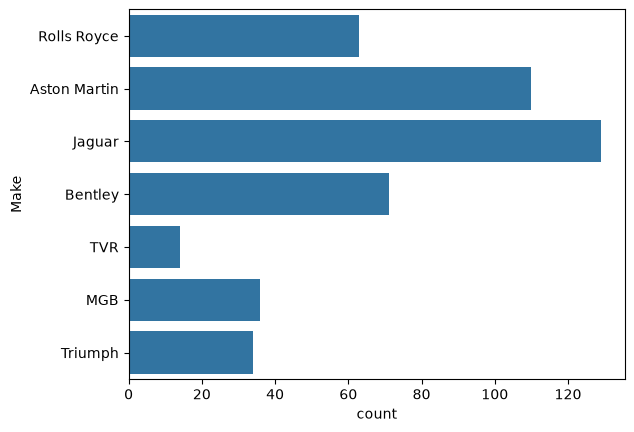

In [47]:
sns.countplot(df['Make'])

* **country wise car sales**

<Axes: >

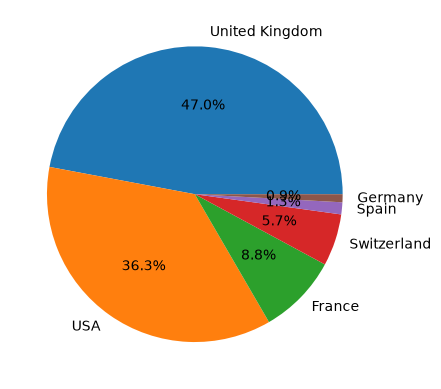

In [50]:
df['CountryName'].value_counts().plot(kind='pie',autopct = '%.1f%%')

* **Car Modelwise Car Sales**

<Axes: xlabel='Model'>

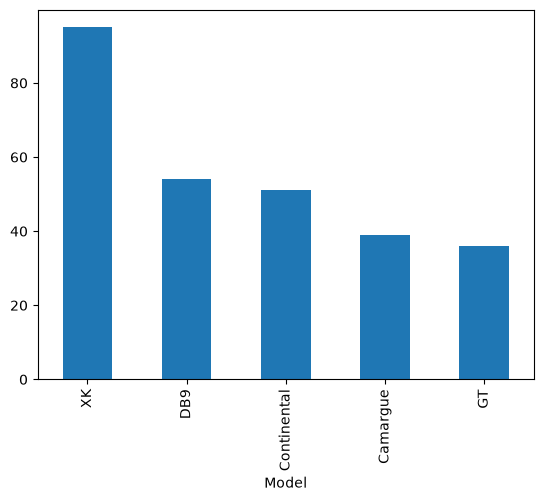

In [56]:
df['Model'].value_counts().head(5).plot(kind='bar')

<Axes: xlabel='Model'>

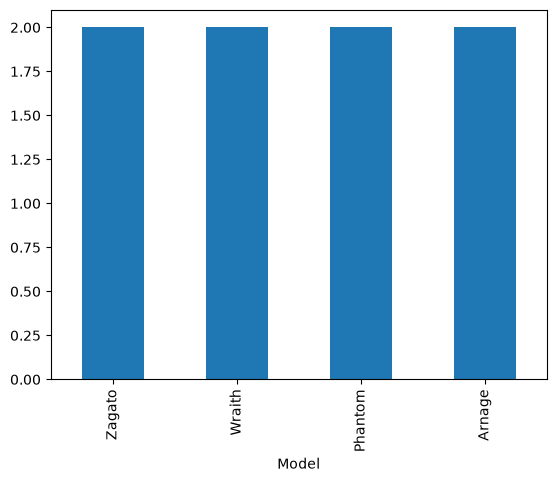

In [61]:
df['Model'].value_counts().tail(4).plot(kind='bar')

# Numerical Columns

* **sales price count**

<Axes: xlabel='SalePrice', ylabel='Count'>

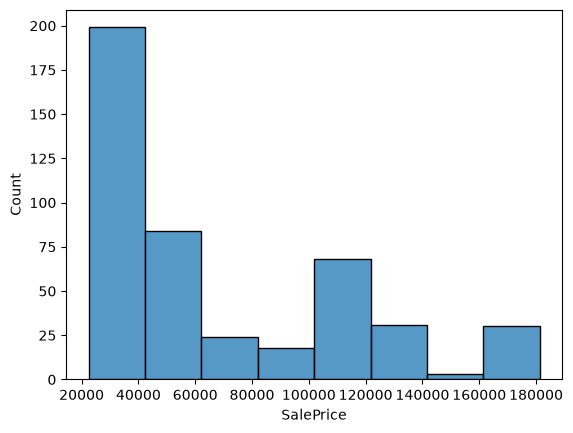

In [66]:
sns.histplot(df['SalePrice'],bins=8)

* **cost price count**

<Axes: xlabel='CostPrice', ylabel='Density'>

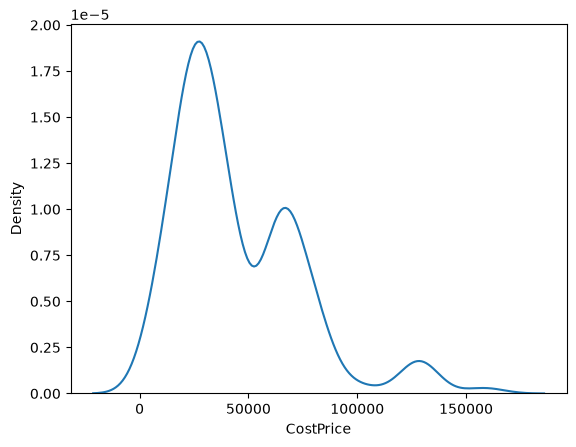

In [70]:
sns.kdeplot(df['CostPrice'])

# 4. Bivariate/Multivariate Analysis – relationships between important variables

C:\Users\Kishor\AppData\Local\Temp\ipykernel_9360\1007737621.py:2: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=make_revenue.values, y=make_revenue.index, palette='magma')


Text(0.5, 1.0, 'Bivariate: Total Revenue Generated by Car Make')

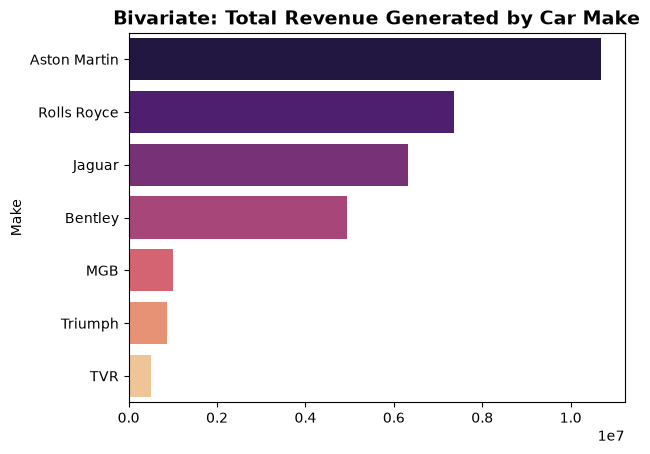

In [26]:
make_revenue = df.groupby('Make')['SalePrice'].sum().sort_values(ascending=False)
sns.barplot(x=make_revenue.values, y=make_revenue.index, palette='magma')
plt.title('Bivariate: Total Revenue Generated by Car Make', fontsize=14, fontweight='bold')

* **country wise SalesPrice**

<Axes: xlabel='CountryName', ylabel='SalePrice'>

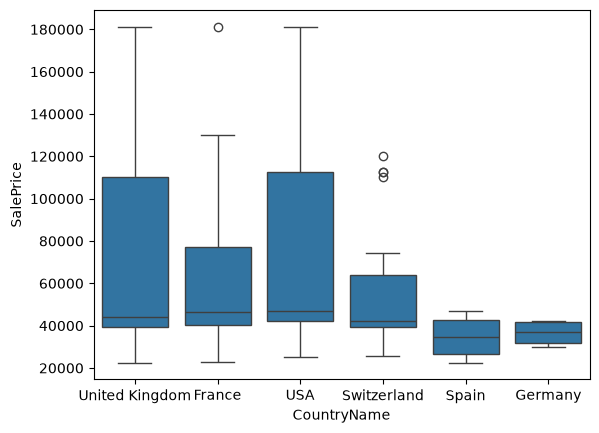

In [78]:
sns.boxplot(x=df['CountryName'],y=df['SalePrice'])

* **Brand wise CostPrice**

<Axes: xlabel='Make', ylabel='CostPrice'>

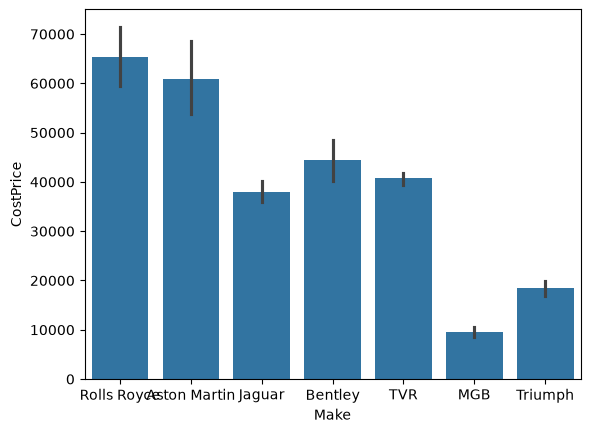

In [8]:
sns.barplot(x=df['Make'],y=df['CostPrice'])

In [9]:
pd.crosstab(df['Make'],df['CountryName'])

CountryName,France,Germany,Spain,Switzerland,USA,United Kingdom
Make,,,,,,
Aston Martin,21,0,0,13,38,38
Bentley,6,0,1,2,27,35
Jaguar,5,2,2,7,52,61
MGB,0,0,0,0,12,24
Rolls Royce,6,0,0,3,21,33
TVR,1,2,1,1,6,3
Triumph,1,0,2,0,10,21


<Axes: xlabel='CountryName', ylabel='Make'>

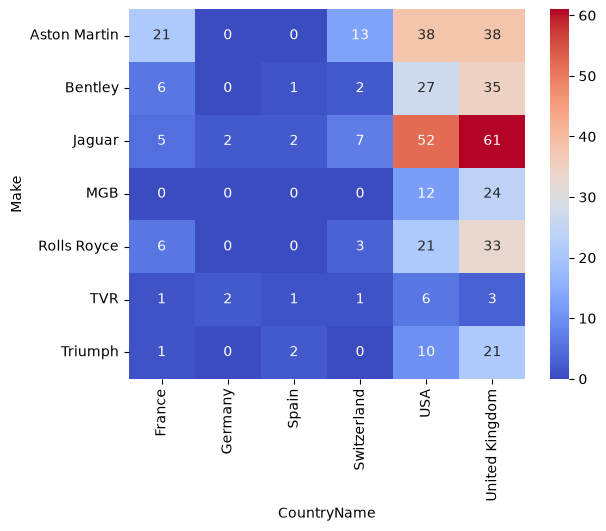

In [10]:
sns.heatmap(pd.crosstab(df['Make'],df['CountryName']),annot=True,cmap="coolwarm")

# 5. Statistical Summary – mean, median, standard deviation, etc.

In [11]:
df.describe()

,InvoiceDate,IsDealer,SalePrice,CostPrice,TotalDiscount,DeliveryCharge,SpareParts,LaborCost,ReportingYear,ReportingMonth,Registration_Date
count,457,0.0,457.000000,457.000000,457.000000,457.000000,457.000000,457.000000,457.000000,457.000000,457
mean,2014-07-15 22:09:42.932166,NaN,69360.919037,44660.601751,492.986915,525.098468,1083.282276,679.426696,2014.072210,6.503282,1999-05-14 10:55:24.288840
min,2012-01-01 00:00:00,NaN,22500.000000,4500.000000,0.000000,-75.000000,50.000000,147.000000,2012.000000,1.000000,1974-09-20 00:00:00
25%,2013-08-02 00:00:00,NaN,39500.000000,22500.000000,150.000000,50.000000,400.000000,325.000000,2013.000000,3.000000,1997-06-01 00:00:00
50%,2014-12-04 00:00:00,NaN,44000.000000,36125.000000,200.000000,425.000000,750.000000,570.000000,2014.000000,6.000000,2005-09-20 00:00:00
75%,2015-06-02 00:00:00,NaN,110000.000000,67000.000000,750.000000,875.000000,1950.000000,987.000000,2015.000000,10.000000,2006-09-20 00:00:00
max,2015-12-02 00:00:00,NaN,181250.000000,160000.000000,5050.000000,1750.000000,4000.000000,1250.000000,2015.000000,12.000000,2010-04-05 00:00:00
std,NaN,NaN,45220.973767,29312.331156,598.466661,525.717285,865.803332,345.839792,1.041483,3.469872,NaN


In [22]:
num_cols = df.select_dtypes(include=['int64', 'float64']).columns
stats_summary = df[num_cols].describe().T[['count', 'mean', 'std', 'min', '25%', '50%', '75%', 'max']]
stats_summary = stats_summary.rename(columns={'50%': 'median'})
print(stats_summary.round(2))

                count      mean       std      min      25%   median  \
SalePrice       457.0  69360.92  45220.97  22500.0  39500.0  44000.0   
CostPrice       457.0  44660.60  29312.33   4500.0  22500.0  36125.0   
TotalDiscount   457.0    492.99    598.47      0.0    150.0    200.0   
DeliveryCharge  457.0    525.10    525.72    -75.0     50.0    425.0   
SpareParts      457.0   1083.28    865.80     50.0    400.0    750.0   
LaborCost       457.0    679.43    345.84    147.0    325.0    570.0   
ReportingYear   457.0   2014.07      1.04   2012.0   2013.0   2014.0   
ReportingMonth  457.0      6.50      3.47      1.0      3.0      6.0   
Profit          457.0  24700.32  35579.51 -62250.0   3750.0  15190.0   

                     75%       max  
SalePrice       110000.0  181250.0  
CostPrice        67000.0  160000.0  
TotalDiscount      750.0    5050.0  
DeliveryCharge     875.0    1750.0  
SpareParts        1950.0    4000.0  
LaborCost          987.0    1250.0  
ReportingYear     20

* **Toatl Profit Brand Wise**

In [49]:
# profit
df['Profit'] = df['SalePrice'] - df['CostPrice']
print(f"the total profit : {df.groupby('Make')['Profit'].sum()} ")


the total profit : Make
Aston Martin    3981270
Bentley         1802550
Jaguar          1419300
MGB              669000
Rolls Royce     3240675
TVR              -71250
Triumph          246500
Name: Profit, dtype: int64 


#  6. Visualizations – suitable and well-labelled charts

Text(0.5, 1.0, 'Brand-Wise Total Profit')

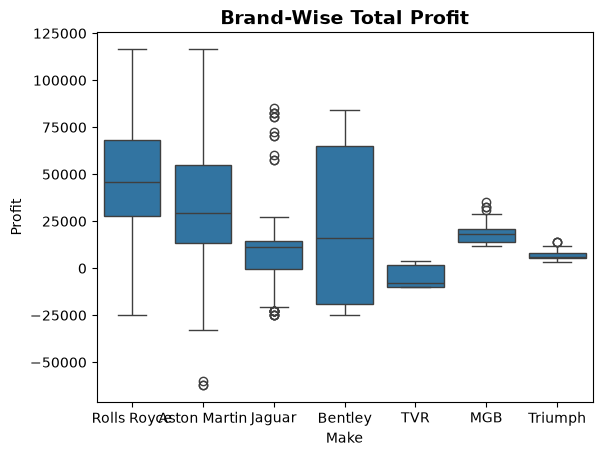

In [43]:
sns.boxplot(x=df['Make'],y=df['Profit'])
plt.title('Brand-Wise Total Profit', fontsize=14, fontweight='bold')

Text(0.5, 1.0, 'Year-Wise Total Profit')

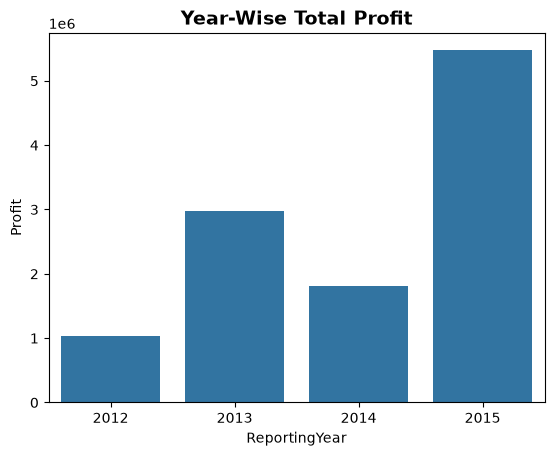

In [30]:
yearly_profit = df.groupby('ReportingYear')['Profit'].sum().reset_index()
sns.barplot(data=yearly_profit, x='ReportingYear', y='Profit', palette='crest')
plt.title('Year-Wise Total Profit', fontsize=14, fontweight='bold')

In [51]:
print(f"the total profit : {df.groupby('ReportingYear')['Profit'].sum()} ")

the total profit : ReportingYear
2012    1033210
2013    2980135
2014    1803360
2015    5471340
Name: Profit, dtype: int64 


Text(0.5, 1.0, 'Month-Wise Total Sales')

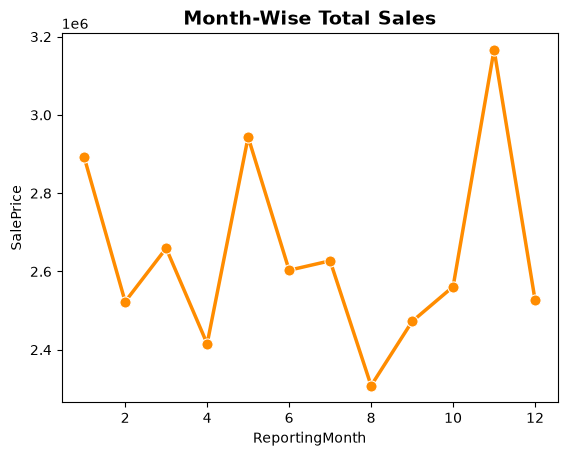

In [37]:
monthly_revenue = df.groupby(['ReportingMonth'])['SalePrice'].sum().reset_index()
sns.lineplot(data=monthly_revenue, x='ReportingMonth', y='SalePrice', marker='o', color='darkorange', linewidth=2.5, markersize=8, sort=False)
plt.title('Month-Wise Total Sales', fontsize=14, fontweight='bold')